In [1]:
import sys
from pathlib import Path

root = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(root / "src"))
print("project root:", root)


project root: e:\Projects\biomed-ml


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu
from biomed.datasets import BonnEEGDataset
from biomed.features import StatsFeatures, BandPowerFeatures, CombinedFeatures

X, y, groups = BonnEEGDataset().load()
fe = CombinedFeatures([StatsFeatures(), BandPowerFeatures()])
F = pd.DataFrame(fe.transform(X), columns=fe.feature_names)
F["y"] = y
print(F.shape)

F.groupby("y")[["ptp", "line_length", "delta_rel", "alpha_rel", "beta_rel", "gamma_rel"]].mean().round(3)


(11500, 22)


,ptp,line_length,delta_rel,alpha_rel,beta_rel,gamma_rel
y,,,,,,
1,1382.224,13004.927,0.101,0.148,0.156,0.003
2,282.689,1631.449,0.224,0.107,0.048,0.004
3,213.740,1515.447,0.234,0.090,0.060,0.005
4,287.543,3526.135,0.074,0.362,0.208,0.011
5,188.862,2166.007,0.127,0.195,0.215,0.012


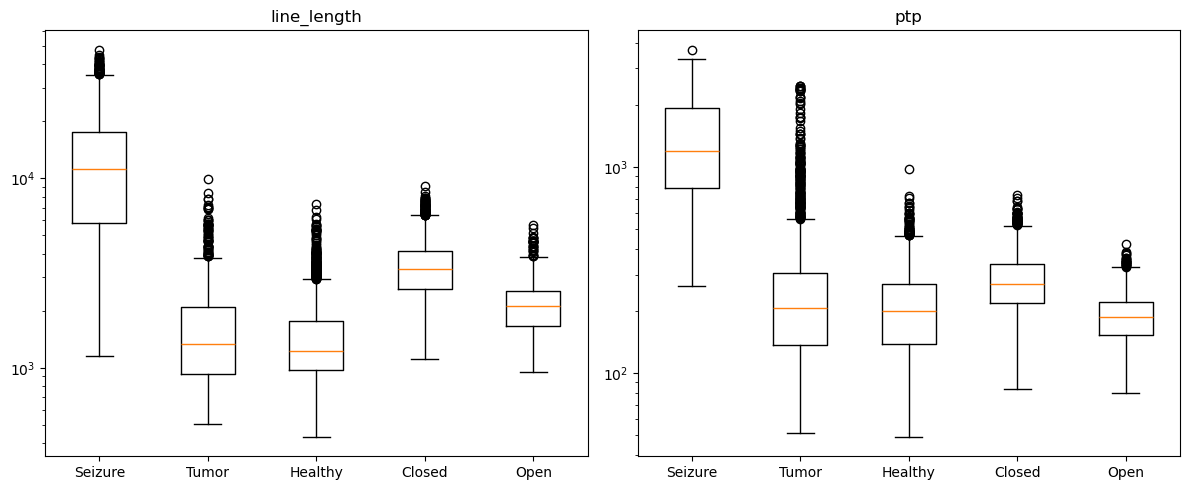

In [3]:
names = ["Seizure", "Tumor", "Healthy", "Closed", "Open"]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, col in zip(axes, ["line_length", "ptp"]):
    data = [F.loc[F["y"] == c, col] for c in [1, 2, 3, 4, 5]]
    ax.boxplot(data)
    ax.set_xticks(range(1, 6), names)
    ax.set_yscale("log")
    ax.set_title(col)
plt.tight_layout()
plt.show()


In [4]:
target = (F["y"] == 1).to_numpy()
n_pos, n_neg = target.sum(), (~target).sum()

scores = {}
for col in fe.feature_names:
    u = mannwhitneyu(F.loc[target, col], F.loc[~target, col]).statistic
    auc = u / (n_pos * n_neg)
    scores[col] = max(auc, 1 - auc)

rank = pd.Series(scores).sort_values(ascending=False)
rank.round(3)


std               0.990
rms               0.989
ptp               0.989
min               0.983
theta_abs         0.978
max               0.977
line_length       0.973
beta_abs          0.965
alpha_abs         0.949
gamma_abs         0.907
delta_abs         0.872
gamma_rel         0.711
theta_rel         0.699
delta_rel         0.684
zero_crossings    0.640
dominant_freq     0.567
beta_rel          0.556
kurtosis          0.553
skew              0.530
mean              0.515
alpha_rel         0.508
dtype: float64

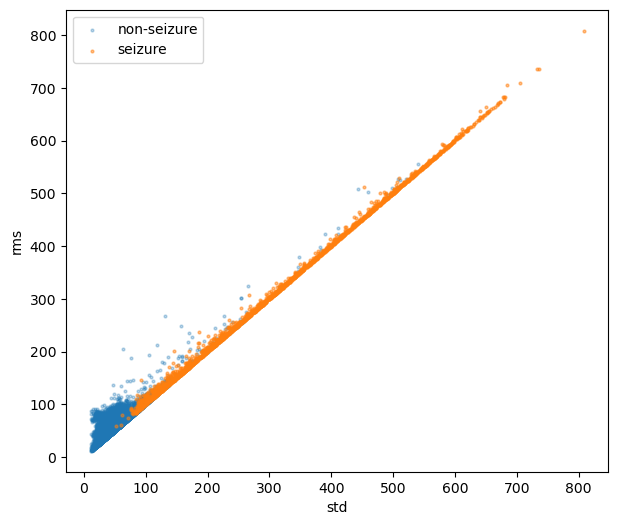

In [5]:
top2 = list(rank.index[:2])

plt.figure(figsize=(7, 6))
plt.scatter(F.loc[~target, top2[0]], F.loc[~target, top2[1]],
            s=4, alpha=0.3, label="non-seizure")
plt.scatter(F.loc[target, top2[0]], F.loc[target, top2[1]],
            s=4, alpha=0.5, label="seizure")
plt.xlabel(top2[0])
plt.ylabel(top2[1])
plt.legend()
plt.show()
